# 실습 05 · Self-Attention·Mask·Heatmap (기본필수)

Attention은 **각 Token이 다른 Token을 얼마나 참고할지** 정하는 계산입니다. 세 단계로 따라갑니다.

`Score (Q·K)` → `Causal Mask (미래 가리기)` → `Softmax Weight (행 합 = 1)` → `Output (Weight × V)`

- **행 = Query**: 지금 계산하는 Token (누가 보는가)
- **열 = Key**: 참고 대상 Token (누구를 보는가)

### 사용 방법
1. **결과는 이미 셀 아래에 저장되어 있습니다.** 읽기만 해도 흐름을 따라갈 수 있어요.
2. 직접 돌려 보려면 `파일 → Drive에 사본 저장`으로 내 사본을 만드세요.
3. 맨 위 **⚙️ 준비 셀을 먼저 한 번 실행**한 뒤, 보고 싶은 구간의 셀을 실행하세요. 각 구간은 준비 셀만 있으면 따로 실행됩니다.
4. **✏️ 표시 셀**은 오른쪽 슬라이더·체크박스의 값을 바꾸고 실행해 보세요. 코드의 값도 함께 바뀝니다.

In [1]:
#@title ⚙️ 먼저 실행하세요 — 실습 공통 코드 준비
# ── 원본: 20261113/mentor/01_basic/common/support.py (그대로 포함) ──
"""강의 공통 오프라인 계산 도구: 실제 사전학습 LLM이 아닙니다.

교육용 정규표현식 토큰화·작은 벡터·가중치 계산만 제공합니다.
Transformer의 tokenizer/embedding 품질을 이 도구로 평가할 수 없습니다.
"""
from pathlib import Path
import json
import math
import re
import torch

DATA = [
    {"id":"A", "title":"실습 파일 보관", "content":"실습 파일은 개인 폴더에 보관합니다.", "category":"learning"},
    {"id":"B", "title":"서버 실행", "content":"프로젝트 폴더에서 서버를 실행합니다.", "category":"environment"},
    {"id":"C", "title":"질문 작성", "content":"오류 메시지와 시도한 작업을 함께 적습니다.", "category":"learning"},
]
SPECIAL = ["[PAD]", "[UNK]", "[BOS]", "[EOS]"]

def words(text: str) -> list[str]:
    """교육용: 한글 연속 글자/영문/숫자/문장부호 분리. 서브워드 토크나이저가 아님."""
    return re.findall(r'[가-힣]+|[A-Za-z]+|\d+|[^\w\s]', text)

class ToyTokenizer:
    """BERT tokenizer 대체가 아닌, 오프라인 개념 확인용 규칙 기반 어휘표."""
    def __init__(self, corpus):
        wordset=sorted({word for line in corpus for word in words(line)})
        self.vocab={tok:i for i,tok in enumerate(SPECIAL + wordset)}
        self.reverse={i:t for t,i in self.vocab.items()}

    def encode(self, text: str, max_length=None, padding_to=None):
        raw=words(text)
        tokens=["[BOS]"]+raw+["[EOS]"]
        truncated=False
        if max_length is not None:
            if max_length<2: raise ValueError("BOS/EOS를 포함하려면 max_length>=2")
            if len(tokens)>max_length:
                tokens=tokens[:max_length-1]+["[EOS]"]
                truncated=True
        valid=len(tokens)
        if padding_to is not None:
            if padding_to<valid: raise ValueError("padding_to must be >= valid length")
            tokens=tokens+["[PAD]"]*(padding_to-valid)
        ids=[self.vocab.get(t,self.vocab["[UNK]"]) for t in tokens]
        mask=[0 if t=="[PAD]" else 1 for t in tokens]
        return {"tokens":tokens,"input_ids":ids,"attention_mask":mask,
                "valid_length":valid,"truncated":truncated,"original_length":len(raw)+2}

    def batch(self, texts, max_length=None):
        items=[self.encode(t,max_length=max_length) for t in texts]
        max_size=max(len(i["input_ids"]) for i in items)
        return [self.encode(t,max_length=max_length,padding_to=max_size) for t in texts]

def context_budget(window, parts:dict, output_reserved:int):
    used=sum(parts.values())
    return {"window":window,"input_used":used,"output_reserved":output_reserved,
            "remaining":window-used-output_reserved,
            "fits":used+output_reserved<=window}

def cosine(a,b):
    a=torch.as_tensor(a,dtype=torch.float32)
    b=torch.as_tensor(b,dtype=torch.float32)
    return float(torch.nn.functional.cosine_similarity(a,b,dim=0))

def attention(q,k,v,causal=True):
    q=torch.as_tensor(q,dtype=torch.float32)
    k=torch.as_tensor(k,dtype=torch.float32)
    v=torch.as_tensor(v,dtype=torch.float32)
    scores=q@k.T/math.sqrt(q.shape[-1])
    mask=torch.triu(torch.ones_like(scores,dtype=torch.bool),diagonal=1)
    weights=torch.softmax(scores.masked_fill(mask,float('-inf')) if causal else scores,dim=-1)
    return scores,weights,weights@v,mask

def write_json(path, data):
    p=Path(path);p.parent.mkdir(exist_ok=True,parents=True)
    p.write_text(json.dumps(data,ensure_ascii=False,indent=2),encoding='utf-8')

def write_md(path,text):
    p=Path(path);p.parent.mkdir(exist_ok=True,parents=True)
    p.write_text(text,encoding='utf-8')

def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

# ── 노트북 전용 준비 ──
import pandas as pd
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
torch.set_num_threads(1)

# 실습 입력 (main.py와 같은 값): Token 3개, 각 2차원. Q = K = V
q = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
k, v = q.clone(), q.clone()
TOKENS = ["t0", "t1", "t2"]

def heatmap(matrix, title, digits=2):
    """행 = Query, 열 = Key. -inf 칸은 회색으로 표시"""
    m = matrix.detach().numpy().astype(float)
    shown = np.where(np.isinf(m), np.nan, m)
    fig, ax = plt.subplots(figsize=(3.6, 3.2))
    ax.imshow(shown, cmap="Blues")
    ax.set_facecolor("#dddddd")
    lo, hi = np.nanmin(shown), np.nanmax(shown)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            text = "-inf" if np.isinf(m[i, j]) else f"{m[i, j]:.{digits}f}"
            dark = not np.isinf(m[i, j]) and hi > lo and (m[i, j] - lo) / (hi - lo) > 0.6
            ax.text(j, i, text, ha="center", va="center", fontsize=11,
                    color="white" if dark else "black")
    ax.set_xticks(range(m.shape[1]), TOKENS[:m.shape[1]])
    ax.set_yticks(range(m.shape[0]), TOKENS[:m.shape[0]])
    ax.set_xlabel("Key (looked at)"); ax.set_ylabel("Query (looking)")
    ax.set_title(title)
    plt.show()

def table(t, digits=4):
    return pd.DataFrame(t.detach().numpy(), index=[f"Q:{n}" for n in TOKENS],
                        columns=[f"K:{n}" for n in TOKENS]).round(digits)

print("준비 완료 ✅  q shape:", list(q.shape))

준비 완료 ✅  q shape: [3, 2]


## 0. 입력 Q, K, V
이 실습에서는 Q, K, V를 모두 같은 값으로 둡니다. Token 3개 × 숫자 2개입니다.

In [2]:
pd.DataFrame(q.numpy(), index=TOKENS, columns=["x1", "x2"])

,x1,x2
t0,1.0,0.0
t1,0.0,1.0
t2,1.0,1.0


## B01. Score 계산

$$\text{Score} = \frac{Q K^T}{\sqrt{d_k}}$$

Q의 행과 K의 행을 내적해서 **얼마나 잘 맞는지** 점수를 매깁니다. $\sqrt{d_k}$로 나누는 것은 차원이 커져도 점수가 너무 커지지 않게 하려는 것입니다.

### B01-1. 내적만 먼저

In [3]:
raw = q @ k.T
table(raw)

,K:t0,K:t1,K:t2
Q:t0,1.0,0.0,1.0
Q:t1,0.0,1.0,1.0
Q:t2,1.0,1.0,2.0


In [4]:
d_k = q.shape[-1]
print("d_k =", d_k, " → √d_k =", round(math.sqrt(d_k), 4))

d_k = 2  → √d_k = 1.4142


### B01-2. √d_k로 나눈 Score

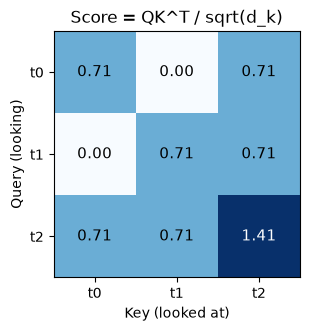

In [5]:
scores = q @ k.T / math.sqrt(q.shape[-1])
heatmap(scores, "Score = QK^T / sqrt(d_k)")

> Score는 아직 **확률이 아닙니다.** 행을 더해도 1이 아니고 크기도 제각각입니다.

In [6]:
print("Score 각 행의 합:", scores.sum(dim=-1).round(decimals=4).tolist())
assert scores.shape == (3, 3)
print("B01 통과 ✅ shape", tuple(scores.shape))

Score 각 행의 합: [1.414199948310852, 1.414199948310852, 2.828399896621704]
B01 통과 ✅ shape (3, 3)


## B02. Causal Mask: 미래 가리기

문장을 앞에서부터 만들 때, 지금 Token은 **아직 나오지 않은 뒤 Token을 보면 안 됩니다.** 대각선 위쪽(미래)을 `True`로 표시해 막습니다.

In [7]:
scores = q @ k.T / math.sqrt(q.shape[-1])
mask = torch.triu(torch.ones(3, 3, dtype=torch.bool), diagonal=1)
table(mask)

,K:t0,K:t1,K:t2
Q:t0,False,True,True
Q:t1,False,False,True
Q:t2,False,False,False


막을 칸에 `-inf`를 넣습니다. Softmax에서 `-inf`는 0이 됩니다.

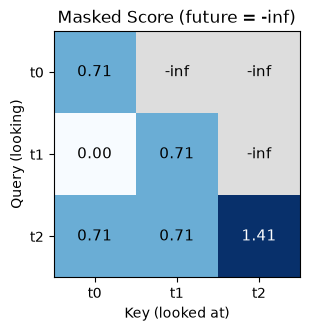

In [8]:
masked_scores = scores.masked_fill(mask, float("-inf"))
heatmap(masked_scores, "Masked Score (future = -inf)")

## B03. Softmax로 Weight 만들기

각 행에 Softmax를 적용하면 **행 합이 1인 비율**이 됩니다. 이것이 "얼마나 참고할지"입니다.

### B03-1. 한 행만 직접 계산 (t1 행)

In [9]:
scores = q @ k.T / math.sqrt(q.shape[-1])
mask = torch.triu(torch.ones(3, 3, dtype=torch.bool), diagonal=1)
masked_scores = scores.masked_fill(mask, float("-inf"))

row = masked_scores[1]
print("Score 행  :", row.tolist())
print("exp(Score):", row.exp().round(decimals=4).tolist(), " ← exp(-inf) = 0")
print("합계       :", round(row.exp().sum().item(), 4))
print("비율       :", (row.exp() / row.exp().sum()).round(decimals=4).tolist())

Score 행  : [0.0, 0.7071067690849304, -inf]
exp(Score): [1.0, 2.02810001373291, 0.0]  ← exp(-inf) = 0
합계       : 3.0281
비율       : [0.3301999866962433, 0.6697999835014343, 0.0]


### B03-2. 전체 Weight

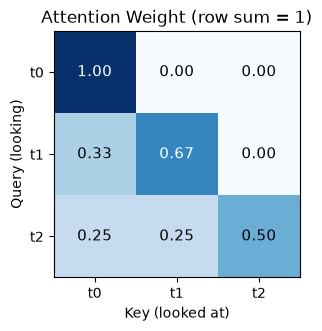

In [10]:
weights = torch.softmax(masked_scores, dim=-1)
heatmap(weights, "Attention Weight (row sum = 1)")

In [11]:
row_sums = weights.sum(dim=-1)
print("행 합       :", row_sums.tolist())
print("마스크 칸 값:", weights[mask].tolist())
assert torch.allclose(row_sums, torch.ones(3), atol=1e-6)
assert torch.all(weights[mask] == 0)
print("B03 통과 ✅ 예상 [[1,0,0],[0.33,0.67,0],[0.25,0.25,0.5]]")

행 합       : [1.0, 1.0, 1.0]
마스크 칸 값: [0.0, 0.0, 0.0]
B03 통과 ✅ 예상 [[1,0,0],[0.33,0.67,0],[0.25,0.25,0.5]]


### B03-3. 비교: Mask가 없으면?
t0도 뒤 Token을 참고하게 됩니다. 문장을 만드는 모델에서는 **답을 미리 보는 것**과 같아서 막아야 합니다.

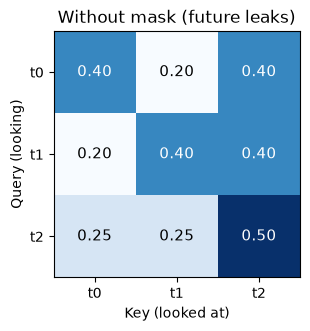

In [12]:
heatmap(torch.softmax(scores, dim=-1), "Without mask (future leaks)")

## B04. Output = Weight × V
Weight 비율대로 V를 섞어 Token마다 새 벡터를 만듭니다. t0는 자기 자신만, t2는 세 Token을 모두 섞습니다.

In [13]:
output = weights @ v
pd.DataFrame(output.numpy(), index=TOKENS, columns=["x1", "x2"]).round(4)

,x1,x2
t0,1.0000,0.0000
t1,0.3302,0.6698
t2,0.7517,0.7517


### ✏️ 직접 해 보기 — t2의 Query를 움직여 보세요

t2 행 Weight: [0.24799999594688416, 0.24799999594688416, 0.503000020980835]


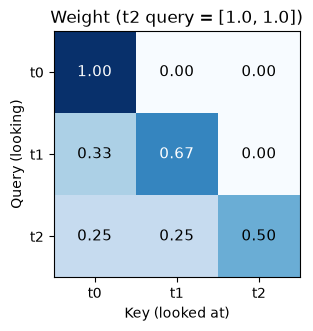

In [14]:
#@title ✏️ t2의 Query 값과 Mask 사용 여부를 바꿔 보세요
t2_x1 = 1.0  #@param {type:"slider", min:-3, max:3, step:0.5}
t2_x2 = 1.0  #@param {type:"slider", min:-3, max:3, step:0.5}
use_causal_mask = True  #@param {type:"boolean"}

my_q = q.clone()
my_q[2] = torch.tensor([t2_x1, t2_x2])
_, my_weights, _, _ = attention(my_q, k, v, causal=use_causal_mask)
print("t2 행 Weight:", my_weights[2].round(decimals=3).tolist())
heatmap(my_weights, f"Weight (t2 query = [{t2_x1}, {t2_x2}])")

## 저장. 결과 저장 (`main.py`와 같은 결과)
Score·Mask·Weight·행 합·Output을 `outputs/attention_report.json`으로 저장합니다. 이 셀은 준비 셀만 있으면 혼자 실행됩니다.

In [15]:
scores = q @ k.T / math.sqrt(q.shape[-1])
assert scores.shape == (3, 3)
mask = torch.triu(torch.ones(3, 3, dtype=torch.bool), diagonal=1)
masked_scores = scores.masked_fill(mask, float("-inf"))
weights = torch.softmax(masked_scores, dim=-1)
row_sums = weights.sum(dim=-1)
assert torch.allclose(row_sums, torch.ones(3), atol=1e-6)
assert torch.all(weights[mask] == 0)
output = weights @ v

write_json(OUT_DIR / "attention_report.json", {
    "scores": scores.tolist(), "causal_mask": mask.tolist(),
    "weights": weights.tolist(), "row_sums": row_sums.tolist(),
    "output": output.tolist(), "no_mask_weights": torch.empty(0).tolist(),
    "masked_vs_unmasked_l1": None, "multi_head": {},
    "limits": ["Attention Weight만으로 모델의 최종 판단 전체를 설명할 수 없다"],
})
print("[05]", weights.round(decimals=2).tolist(), "row_sums", row_sums.tolist())

[05] [[1.0, 0.0, 0.0], [0.33000001311302185, 0.6700000166893005, 0.0], [0.25, 0.25, 0.5]] row_sums [1.0, 1.0, 1.0]


In [16]:
#@title 📥 결과 파일 내려받기 (Colab)
if IN_COLAB:
    from google.colab import files
    for name in ['attention_report.json']:
        files.download(str(OUT_DIR / name))
else:
    print("Colab에서 실행하면 결과 파일이 내려받아집니다:", ['attention_report.json'])

Colab에서 실행하면 결과 파일이 내려받아집니다: ['attention_report.json']


---
### 정리
- **Score** = Q·Kᵀ / √d_k. 확률이 아니다.
- **Causal Mask**는 대각선 위(미래)를 -inf로 막는다. 행 = Query, 열 = Key.
- **Softmax Weight**는 행 합 = 1, 마스크 칸 = 0. 예상 `[[1,0,0],[0.33,0.67,0],[0.25,0.25,0.5]]`.
- Attention Weight만으로 모델의 판단 전체를 설명할 수는 없다.